In [1]:
import random
import numpy as np
import torch
from torch.utils.tensorboard import SummaryWriter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 1. Dataset

We use the **RSICD** (Remote Sensing Image Captioning Dataset) via the Hugging Face Hub. Each image has 5 reference captions written by different annotators.

In [2]:
import json
from pathlib import Path

DATA_ROOT = Path("data/rsicd")
IMAGES_ROOT = DATA_ROOT / "images"
CAPTIONS_ROOT = DATA_ROOT / "captions"


def load_split(split):
    with open(CAPTIONS_ROOT / f"{split}.json", "r", encoding="utf-8") as f:
        return json.load(f)


train_data = load_split("train")
valid_data = load_split("valid")
test_data = load_split("test")

print(f"Train: {len(train_data)} images")
print(f"Valid: {len(valid_data)} images")
print(f"Test:  {len(test_data)} images")

sample = train_data[0]
print(f"\nSample entry:")
print(f"  filename: {sample['filename']}")
print(f"  number of captions: {len(sample['captions'])}")
for i, cap in enumerate(sample['captions']):
    print(f"  [{i}] {cap}")

Train: 8734 images
Valid: 1094 images
Test:  1093 images

Sample entry:
  filename: airport_1.jpg
  number of captions: 5
  [0] Many aircraft are parked next to a long building in an airport.
  [1] Many planes are parked next to a long building at an airport.
  [2] Many planes are parked next to a long building in an airport.
  [3] many planes are parked next to a long building at an airport.
  [4] many planes are parked next to a long building in an airport .


### Visualization

A quick look at a few examples: each image with its 5 reference captions.

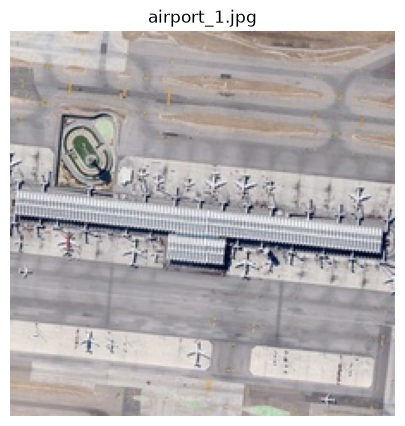

Captions:
  [0] Many aircraft are parked next to a long building in an airport.
  [1] Many planes are parked next to a long building at an airport.
  [2] Many planes are parked next to a long building in an airport.
  [3] many planes are parked next to a long building at an airport.
  [4] many planes are parked next to a long building in an airport .



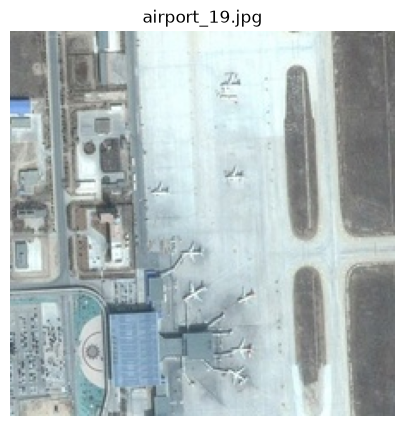

Captions:
  [0] some planes are in an airport near several buildings and a parking lot.
  [1] some planes are located at an airport near several buildings and a parking lot.
  [2] some planes are in an airport near several buildings and a parking lot.
  [3] some planes are in an airport near several buildings and a parking lot.
  [4] some planes are in an airport near several buildings and a parking lot .



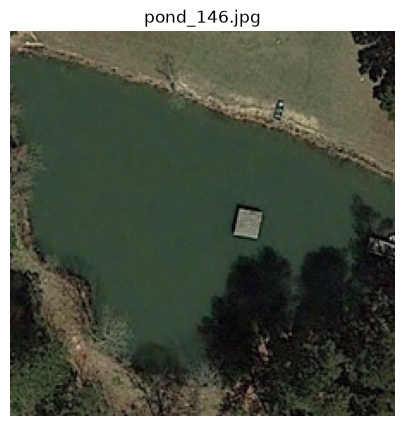

Captions:
  [0] a triangular pond is surrounded by some green trees.
  [1] a triangular pond is surrounded by some green trees.
  [2] a triangular lake is surrounded by some green trees.
  [3] a triangular lake is surrounded by some green trees.
  [4] a triangular pond is surrounded by some green trees .



In [3]:
import matplotlib.pyplot as plt
from PIL import Image

def show_sample(entry, split="train"):
    img_path = IMAGES_ROOT / split / entry["filename"]
    img = Image.open(img_path)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(entry["filename"])
    plt.show()

    print("Captions:")
    for i, cap in enumerate(entry["captions"]):
        print(f"  [{i}] {cap}")
    print()


for entry in [train_data[0], train_data[100], train_data[5000]]:
    show_sample(entry)

## 2. Caption statistics

Before building the vocabulary we inspect the caption length distribution on the training set. The 99th percentile of caption length will drive the choice of `MAX_LEN`, the sequence length cap used for padding and truncation.

In [4]:
import re

def tokenize(caption):
    caption = caption.lower()
    caption = re.sub(r"([.,!?;:'\"])", r" \1 ", caption)
    tokens = caption.split()
    return tokens


example = train_data[0]["captions"][0]
print(f"Original: {example}")
print(f"Tokens:   {tokenize(example)}")

Original: Many aircraft are parked next to a long building in an airport.
Tokens:   ['many', 'aircraft', 'are', 'parked', 'next', 'to', 'a', 'long', 'building', 'in', 'an', 'airport', '.']


Total training captions: 43670
  min:    1
  max:    165
  mean:   11.93
  median: 12
  p90:    16
  p95:    18
  p99:    21


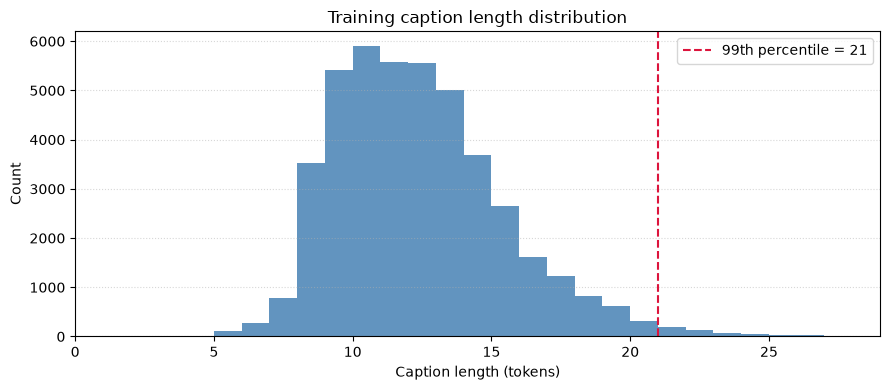

Captions above the 99th percentile (21 tokens): 366 / 43670


In [5]:
train_lengths = [
    len(tokenize(cap))
    for entry in train_data
    for cap in entry["captions"]
]
train_lengths_np = np.array(train_lengths)

print(f"Total training captions: {len(train_lengths)}")
print(f"  min:    {train_lengths_np.min()}")
print(f"  max:    {train_lengths_np.max()}")
print(f"  mean:   {train_lengths_np.mean():.2f}")
print(f"  median: {np.median(train_lengths_np):.0f}")
print(f"  p90:    {np.percentile(train_lengths_np, 90):.0f}")
print(f"  p95:    {np.percentile(train_lengths_np, 95):.0f}")
print(f"  p99:    {np.percentile(train_lengths_np, 99):.0f}")

p99 = np.percentile(train_lengths_np, 99)
cap_max = int(np.percentile(train_lengths_np, 99.9)) + 2

plt.figure(figsize=(9, 4))
plt.hist(train_lengths_np, bins=range(1, train_lengths_np.max() + 2),
         color="steelblue", alpha=0.85)
plt.axvline(p99, color="crimson", linestyle="--", linewidth=1.5,
            label=f"99th percentile = {p99:.0f}")
plt.xlim(0, cap_max)
plt.xlabel("Caption length (tokens)")
plt.ylabel("Count")
plt.title("Training caption length distribution")
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Captions above the 99th percentile ({p99:.0f} tokens): "
      f"{(train_lengths_np > p99).sum()} / {len(train_lengths_np)}")

In [6]:
MAX_LEN = 22
content_budget = MAX_LEN - 2
num_truncated = (train_lengths_np > content_budget).sum()

print(f"MAX_LEN = {MAX_LEN} (allows up to {content_budget} content tokens + <bos> + <eos>)")
print(f"Captions that will be truncated: {num_truncated} / {len(train_lengths_np)} "
      f"({100 * num_truncated / len(train_lengths_np):.2f}%)")

MAX_LEN = 22 (allows up to 20 content tokens + <bos> + <eos>)
Captions that will be truncated: 563 / 43670 (1.29%)


## 3. Vocabulary

The vocabulary is built from the training captions only. We also discard rare words below a minimum frequency threshold `min_freq`, keeping the vocabulary compact and improving training stability.

Four special tokens are added:

- `<pad>`: padding, used to make all sequences in a batch the same length.
- `<bos>`: beginning of sequence, prepended to every caption.
- `<eos>`: end of sequence, appended to every caption.
- `<unk>`: unknown, replaces any word not in the vocabulary (either rare or unseen at test time).

In [7]:
from collections import Counter

word_counts = Counter()
for entry in train_data:
    for cap in entry["captions"]:
        word_counts.update(tokenize(cap))

total_unique = len(word_counts)
total_tokens = sum(word_counts.values())

print(f"Total unique words: {total_unique}")
print(f"Total word occurrences: {total_tokens}")
print()
print("Top 20 most frequent words:")
for word, count in word_counts.most_common(20):
    print(f"  {word:12s} {count:>7d}")

print()
print("Vocabulary size for different min_freq thresholds:")
for min_freq in [1, 2, 3, 5, 10, 20]:
    kept = sum(1 for c in word_counts.values() if c >= min_freq)
    covered_tokens = sum(c for c in word_counts.values() if c >= min_freq)
    coverage = 100 * covered_tokens / total_tokens
    print(f"  min_freq={min_freq:3d} -> {kept:5d} words, "
          f"{coverage:.2f}% of all token occurrences covered")

Total unique words: 2829
Total word occurrences: 521004

Top 20 most frequent words:
  .              43832
  a              41145
  are            25505
  green          21115
  many           18821
  trees          17371
  and            16649
  of             15116
  the            14875
  in             14872
  buildings      14077
  is             11592
  some           10297
  with            9177
  near            6862
  on              6086
  several         5888
  two             5377
  to              5267
  area            5065

Vocabulary size for different min_freq thresholds:
  min_freq=  1 ->  2829 words, 100.00% of all token occurrences covered
  min_freq=  2 ->  1832 words, 99.81% of all token occurrences covered
  min_freq=  3 ->  1442 words, 99.66% of all token occurrences covered
  min_freq=  5 ->  1103 words, 99.44% of all token occurrences covered
  min_freq= 10 ->   804 words, 99.06% of all token occurrences covered
  min_freq= 20 ->   583 words, 98.48% of all to

In [8]:
MIN_FREQ = 5

PAD_IDX, BOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3
special_tokens = ["<pad>", "<bos>", "<eos>", "<unk>"]

kept_words = sorted(
    [w for w, c in word_counts.items() if c >= MIN_FREQ],
    key=lambda w: (-word_counts[w], w),
)

idx2word = special_tokens + kept_words
word2idx = {w: i for i, w in enumerate(idx2word)}

VOCAB_SIZE = len(idx2word)

print(f"Vocabulary size: {VOCAB_SIZE} ({len(special_tokens)} special + {len(kept_words)} words)")
print(f"PAD={PAD_IDX}  BOS={BOS_IDX}  EOS={EOS_IDX}  UNK={UNK_IDX}")
print()
print("First 15 regular tokens (most frequent first):")
for w in idx2word[4:19]:
    print(f"  {word2idx[w]:4d}  {w:12s}  (freq={word_counts[w]})")

Vocabulary size: 1107 (4 special + 1103 words)
PAD=0  BOS=1  EOS=2  UNK=3

First 15 regular tokens (most frequent first):
     4  .             (freq=43832)
     5  a             (freq=41145)
     6  are           (freq=25505)
     7  green         (freq=21115)
     8  many          (freq=18821)
     9  trees         (freq=17371)
    10  and           (freq=16649)
    11  of            (freq=15116)
    12  the           (freq=14875)
    13  in            (freq=14872)
    14  buildings     (freq=14077)
    15  is            (freq=11592)
    16  some          (freq=10297)
    17  with          (freq=9177)
    18  near          (freq=6862)


In [9]:
def encode(caption):
    tokens = tokenize(caption)[: MAX_LEN - 2]
    ids = [BOS_IDX] + [word2idx.get(t, UNK_IDX) for t in tokens] + [EOS_IDX]
    return ids


def decode(ids):
    tokens = []
    for i in ids:
        if i == EOS_IDX:
            break
        if i in (PAD_IDX, BOS_IDX):
            continue
        tokens.append(idx2word[i])
    return " ".join(tokens)


caption = train_data[0]["captions"][0]
ids = encode(caption)
back = decode(ids)

print(f"Original: {caption}")
print(f"Tokens:   {tokenize(caption)}")
print(f"IDs:      {ids}")
print(f"Decoded:  {back}")

Original: Many aircraft are parked next to a long building in an airport.
Tokens:   ['many', 'aircraft', 'are', 'parked', 'next', 'to', 'a', 'long', 'building', 'in', 'an', 'airport', '.']
IDs:      [1, 8, 191, 6, 52, 53, 22, 5, 124, 39, 13, 28, 59, 4, 2]
Decoded:  many aircraft are parked next to a long building in an airport .


## 4. PyTorch Dataset and DataLoader

We now wrap the on-disk data into a `torch.utils.data.Dataset` that returns pairs `(image, caption_ids)` ready to be consumed by the model. Images are resized, converted to tensors and normalized with ImageNet statistics so they match the input distribution expected by a pre-trained ResNet encoder. Captions are encoded through the vocabulary and framed with `<bos>` and `<eos>`.

Since every image comes with 5 reference captions, we treat each `(image, caption)` pair as an independent training example. This expands the effective training set from 8734 to 43670 samples.

A custom `collate_fn` pads caption sequences within each batch so they share a common length, enabling batched training with `batch_size > 1`.

In [10]:
from torchvision import transforms

IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

base_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

train_transform = base_transform
eval_transform = base_transform

print("Transform pipeline:")
print(base_transform)

Transform pipeline:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [11]:
from torch.utils.data import Dataset

class RSICDDataset(Dataset):
    def __init__(self, data, images_dir, transform):
        self.data = data
        self.images_dir = Path(images_dir)
        self.transform = transform

    def __len__(self):
        return len(self.data) * 5

    def __getitem__(self, idx):
        img_idx = idx // 5
        cap_idx = idx % 5

        entry = self.data[img_idx]
        image = Image.open(self.images_dir / entry["filename"]).convert("RGB")
        image = self.transform(image)

        caption_ids = torch.tensor(encode(entry["captions"][cap_idx]), dtype=torch.long)
        return image, caption_ids

In [12]:
train_set = RSICDDataset(train_data, IMAGES_ROOT / "train", train_transform)
valid_set = RSICDDataset(valid_data, IMAGES_ROOT / "valid", eval_transform)
test_set  = RSICDDataset(test_data,  IMAGES_ROOT / "test",  eval_transform)

print(f"Train set: {len(train_set)} samples ({len(train_data)} images x 5 captions)")
print(f"Valid set: {len(valid_set)} samples")
print(f"Test  set: {len(test_set)} samples")

image, caption_ids = train_set[0]
print()
print(f"First training sample:")
print(f"  image tensor shape: {tuple(image.shape)}")
print(f"  image dtype:        {image.dtype}")
print(f"  image min/max:      {image.min().item():.3f} / {image.max().item():.3f}")
print(f"  caption tensor:     {caption_ids}")
print(f"  caption shape:      {tuple(caption_ids.shape)}")
print(f"  decoded caption:    {decode(caption_ids.tolist())}")

Train set: 43670 samples (8734 images x 5 captions)
Valid set: 5470 samples
Test  set: 5465 samples

First training sample:
  image tensor shape: (3, 224, 224)
  image dtype:        torch.float32
  image min/max:      -2.118 / 2.640
  caption tensor:     tensor([  1,   8, 191,   6,  52,  53,  22,   5, 124,  39,  13,  28,  59,   4,
          2])
  caption shape:      (15,)
  decoded caption:    many aircraft are parked next to a long building in an airport .


In [13]:
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

BATCH_SIZE = 32
NUM_WORKERS = 0


def collate_fn(batch):
    images = torch.stack([item[0] for item in batch])
    captions = pad_sequence(
        [item[1] for item in batch],
        batch_first=True,
        padding_value=PAD_IDX,
    )
    return images, captions


train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

valid_loader = DataLoader(
    valid_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
)

print(f"Train batches: {len(train_loader)}")
print(f"Valid batches: {len(valid_loader)}")
print(f"Test  batches: {len(test_loader)}")

Train batches: 1365
Valid batches: 171
Test  batches: 171


In [14]:
images, captions = next(iter(train_loader))

print(f"images shape:   {tuple(images.shape)}")
print(f"captions shape: {tuple(captions.shape)}")
print(f"images dtype:   {images.dtype}")
print(f"captions dtype: {captions.dtype}")
print()

print("First 3 captions in the batch (raw ids):")
for i in range(3):
    print(f"  [{i}] {captions[i].tolist()}")

print()
print("Decoded:")
for i in range(3):
    print(f"  [{i}] {decode(captions[i].tolist())}")

images shape:   (32, 3, 224, 224)
captions shape: (32, 22)
images dtype:   torch.float32
captions dtype: torch.int64

First 3 captions in the batch (raw ids):
  [0] [1, 8, 36, 6, 13, 37, 118, 19, 21, 33, 11, 5, 29, 4, 2, 0, 0, 0, 0, 0, 0, 0]
  [1] [1, 5, 35, 128, 11, 36, 52, 18, 12, 59, 413, 4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  [2] [1, 5, 124, 38, 15, 53, 22, 20, 14, 4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Decoded:
  [0] many cars are in parking lots on two sides of a road .
  [1] a large number of cars parked near the airport plains .
  [2] a long playground is next to several buildings .


## 5. Model: CNN encoder + LSTM decoder

The model follows the *Show and Tell* architecture:

- An **encoder** maps the input image to a fixed-size feature vector. We use a ResNet-50 pre-trained on ImageNet as a frozen feature extractor, replacing its final classification layer with an identity. The 2048-dimensional output is projected to the decoder's hidden size through a small linear layer.
- A **decoder** generates the caption one token at a time with an LSTM, initialized from the image feature. Word indices pass through an embedding layer; the hidden state at each step is projected to the vocabulary through a final linear layer.

For the baseline we use `embedding_dim = 256`, `hidden_dim = 512`, `num_lstm_layers = 1`.

In [15]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights


class EncoderCNN(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        weights = ResNet50_Weights.IMAGENET1K_V2
        backbone = resnet50(weights=weights)

        feature_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone

        for p in self.backbone.parameters():
            p.requires_grad = False

        self.project = nn.Linear(feature_dim, hidden_dim)

    def unfreeze_last_block(self):
        for p in self.backbone.layer4.parameters():
            p.requires_grad = True

    def forward(self, images):
        features = self.backbone(images)
        features = self.project(features)
        return features

In [16]:
class DecoderLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, pad_idx, dropout=0.0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.embedding_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
        )
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_dim, vocab_size)
        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

    def init_state(self, image_features):
        batch_size = image_features.size(0)
        h0 = image_features.unsqueeze(0).expand(self.num_layers, batch_size, self.hidden_dim).contiguous()
        c0 = torch.zeros_like(h0)
        return h0, c0

    def forward(self, caption_ids, image_features):
        embeddings = self.embedding(caption_ids)
        embeddings = self.embedding_dropout(embeddings)
        h0, c0 = self.init_state(image_features)
        outputs, _ = self.lstm(embeddings, (h0, c0))
        outputs = self.output_dropout(outputs)
        logits = self.output(outputs)
        return logits

In [18]:
class ShowAndTell(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, num_layers, pad_idx, dropout=0.0):
        super().__init__()
        self.encoder = EncoderCNN(hidden_dim)
        self.decoder = DecoderLSTM(vocab_size, embedding_dim, hidden_dim, num_layers, pad_idx, dropout=dropout)

    def forward(self, images, caption_ids):
        features = self.encoder(images)
        decoder_input = caption_ids[:, :-1]
        logits = self.decoder(decoder_input, features)
        return logits

    @torch.no_grad()
    def generate(self, images, bos_idx, eos_idx, max_len):
        self.eval()
        batch_size = images.size(0)
        device = images.device

        features = self.encoder(images)
        h, c = self.decoder.init_state(features)

        current_token = torch.full((batch_size, 1), bos_idx, dtype=torch.long, device=device)
        finished = torch.zeros(batch_size, dtype=torch.bool, device=device)
        generated = []

        for _ in range(max_len - 1):
            embeddings = self.decoder.embedding(current_token)
            output, (h, c) = self.decoder.lstm(embeddings, (h, c))
            logits = self.decoder.output(output.squeeze(1))
            next_token = logits.argmax(dim=-1)

            next_token = torch.where(finished, torch.tensor(eos_idx, device=device), next_token)
            generated.append(next_token)
            finished = finished | (next_token == eos_idx)

            if finished.all():
                break

            current_token = next_token.unsqueeze(1)

        return torch.stack(generated, dim=1)

    @torch.no_grad()
    def generate_beam(self, image, bos_idx, eos_idx, max_len, beam_width=5, length_alpha=0.7):
        self.eval()
        device = image.device

        features = self.encoder(image.unsqueeze(0) if image.dim() == 3 else image)
        h, c = self.decoder.init_state(features)

        beams = [{
            "tokens": [bos_idx],
            "log_prob": 0.0,
            "h": h,
            "c": c,
            "finished": False,
        }]

        for _ in range(max_len - 1):
            if all(b["finished"] for b in beams):
                break

            candidates = []
            for beam in beams:
                if beam["finished"]:
                    candidates.append(beam)
                    continue

                last_token = torch.tensor([[beam["tokens"][-1]]], device=device)
                embeddings = self.decoder.embedding(last_token)
                output, (new_h, new_c) = self.decoder.lstm(embeddings, (beam["h"], beam["c"]))
                logits = self.decoder.output(output.squeeze(1))
                log_probs = torch.log_softmax(logits, dim=-1).squeeze(0)

                topk_log_probs, topk_tokens = log_probs.topk(beam_width)

                for log_p, tok in zip(topk_log_probs.tolist(), topk_tokens.tolist()):
                    candidates.append({
                        "tokens": beam["tokens"] + [tok],
                        "log_prob": beam["log_prob"] + log_p,
                        "h": new_h,
                        "c": new_c,
                        "finished": (tok == eos_idx),
                    })

            def score(b):
                length = max(len(b["tokens"]) - 1, 1)
                return b["log_prob"] / (length ** length_alpha)

            candidates.sort(key=score, reverse=True)
            beams = candidates[:beam_width]

        best = max(beams, key=score)
        return best["tokens"][1:]

In [19]:
EMBEDDING_DIM = 256
HIDDEN_DIM = 512
NUM_LAYERS = 1

model = ShowAndTell(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    pad_idx=PAD_IDX,
).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print(f"Total parameters:     {total_params:>12,}")
print(f"Trainable parameters: {trainable_params:>12,}")
print(f"Frozen parameters:    {frozen_params:>12,}")
print()
print(f"Trainable / Total: {100 * trainable_params / total_params:.2f}%")
print()

images, captions = next(iter(train_loader))
images = images.to(device)
captions = captions.to(device)

model.eval()
with torch.no_grad():
    logits = model(images, captions)

print(f"Input images shape:   {tuple(images.shape)}")
print(f"Input captions shape: {tuple(captions.shape)}")
print(f"Output logits shape:  {tuple(logits.shape)}")

Total parameters:       26,985,363
Trainable parameters:    3,477,331
Frozen parameters:      23,508,032

Trainable / Total: 12.89%

Input images shape:   (32, 3, 224, 224)
Input captions shape: (32, 22)
Output logits shape:  (32, 21, 1107)


## 6. Training loop

The model is trained with teacher forcing: at every time step the decoder receives the ground-truth previous token and must predict the next one. We use cross-entropy loss (ignoring padding positions) and the Adam optimizer.

At the end of each epoch we compute the validation loss on the `valid` split (no gradient update). The checkpoint with the lowest validation loss is kept as the best model.

In [20]:
LEARNING_RATE = 1e-4
RUN_NAME = "baseline"

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
)
writer = SummaryWriter(log_dir=f"runs/{RUN_NAME}")

print(f"Loss: {criterion}")
print(f"Optimizer: Adam, lr={LEARNING_RATE}")
print(f"TensorBoard log dir: runs/{RUN_NAME}")

Loss: CrossEntropyLoss()
Optimizer: Adam, lr=0.0001
TensorBoard log dir: runs/baseline


In [21]:
from tqdm import tqdm


def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    total_tokens = 0

    for images, captions in tqdm(loader, desc="train", leave=False):
        images = images.to(device)
        captions = captions.to(device)

        logits = model(images, captions)
        targets = captions[:, 1:]

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            targets.reshape(-1),
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        num_tokens = (targets != PAD_IDX).sum().item()
        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    return total_loss / total_tokens

In [22]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_tokens = 0

    for images, captions in tqdm(loader, desc="eval", leave=False):
        images = images.to(device)
        captions = captions.to(device)

        logits = model(images, captions)
        targets = captions[:, 1:]

        loss = criterion(
            logits.reshape(-1, logits.size(-1)),
            targets.reshape(-1),
        )

        num_tokens = (targets != PAD_IDX).sum().item()
        total_loss += loss.item() * num_tokens
        total_tokens += num_tokens

    return total_loss / total_tokens

In [28]:
from pathlib import Path

NUM_EPOCHS = 15
PATIENCE = 3
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

best_val_loss = float("inf")
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": []}

for epoch in range(1, NUM_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss = evaluate(model, valid_loader, criterion, device)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    writer.add_scalar("loss/train", train_loss, epoch)
    writer.add_scalar("loss/val", val_loss, epoch)

    improved = val_loss < best_val_loss
    marker = " <- new best" if improved else ""
    print(f"Epoch {epoch:2d}/{NUM_EPOCHS} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}{marker}")

    if improved:
        best_val_loss = val_loss
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "val_loss": val_loss,
        }, CHECKPOINT_DIR / f"{RUN_NAME}_best.pt")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f"Early stopping triggered after {epoch} epochs")
            break

writer.close()
print(f"\nBest validation loss: {best_val_loss:.4f}")

Epoch  1/15 | train loss: 2.5815 | val loss: 2.0730 <- new best


Epoch  2/15 | train loss: 1.7094 | val loss: 1.8625 <- new best


Epoch  3/15 | train loss: 1.4861 | val loss: 1.7970 <- new best


Epoch  4/15 | train loss: 1.3558 | val loss: 1.7484 <- new best


Epoch  5/15 | train loss: 1.2626 | val loss: 1.7262 <- new best


...

Epoch  7/15 | train loss: 1.1302 | val loss: 1.7298


Epoch  8/15 | train loss: 1.0780 | val loss: 1.7235 <- new best


Epoch  9/15 | train loss: 1.0309 | val loss: 1.7505


Epoch 10/15 | train loss: 0.9884 | val loss: 1.7526


Epoch 11/15 | train loss: 0.9493 | val loss: 1.7522
Early stopping triggered after 11 epochs

Best validation loss: 1.7235


In [23]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ea = EventAccumulator("runs/baseline")
ea.Reload()

train_loss = [e.value for e in ea.Scalars("loss/train")]
val_loss = [e.value for e in ea.Scalars("loss/val")]

history = {"train_loss": train_loss, "val_loss": val_loss}
print(f"Loaded history: {len(train_loss)} epochs")
print(f"Train losses: {[f'{v:.4f}' for v in train_loss]}")
print(f"Val losses:   {[f'{v:.4f}' for v in val_loss]}")

Loaded history: 11 epochs
Train losses: ['2.5815', '1.7094', '1.4861', '1.3558', '1.2626', '1.1909', '1.1302', '1.0780', '1.0309', '0.9884', '0.9493']
Val losses:   ['2.0730', '1.8625', '1.7970', '1.7484', '1.7262', '1.7254', '1.7298', '1.7235', '1.7505', '1.7526', '1.7522']


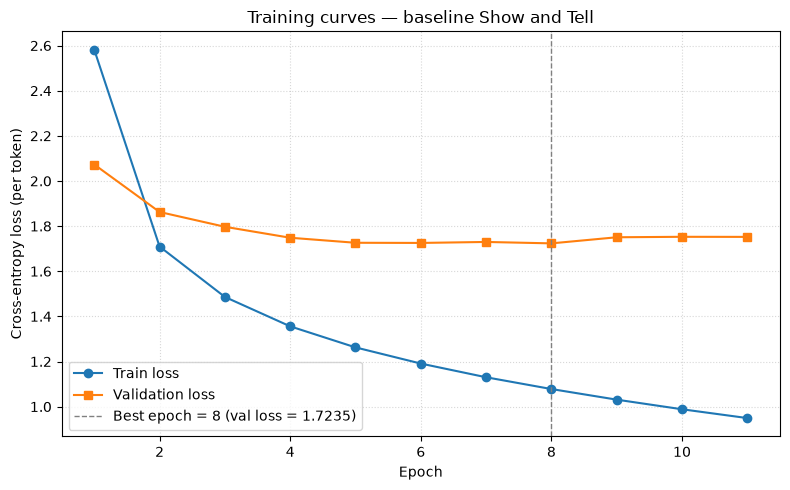

Figure saved to docs/figures/baseline_loss_curves.png


In [24]:
epochs = range(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1
best_val = min(history["val_loss"])

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Train loss")
plt.plot(epochs, history["val_loss"], marker="s", label="Validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", linewidth=1,
            label=f"Best epoch = {best_epoch} (val loss = {best_val:.4f})")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss (per token)")
plt.title("Training curves — baseline Show and Tell")
plt.legend()
plt.grid(linestyle=":", alpha=0.5)
plt.tight_layout()

plt.savefig("docs/figures/baseline_loss_curves.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Figure saved to docs/figures/baseline_loss_curves.png")

## 7. Caption generation and evaluation

We now evaluate the model on its actual task: given an image, generate a caption from scratch.

For this baseline we use **greedy decoding**: at each step we pick the token with the highest predicted probability. We will later compare it against beam search as one of the improvements.

Captions generated this way are compared against the 5 reference captions per image using **BLEU-1/2/3/4**, **ROUGE-L** e **CIDEr**.

In [25]:
checkpoint_path = CHECKPOINT_DIR / "baseline_best.pt" if "CHECKPOINT_DIR" in dir() else Path("checkpoints/baseline_best.pt")

checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

print(f"Loaded checkpoint:")
print(f"  file:      {checkpoint_path}")
print(f"  epoch:     {checkpoint['epoch']}")
print(f"  val loss:  {checkpoint['val_loss']:.4f}")

Loaded checkpoint:
  file:      checkpoints\baseline_best.pt
  epoch:     8
  val loss:  1.7235


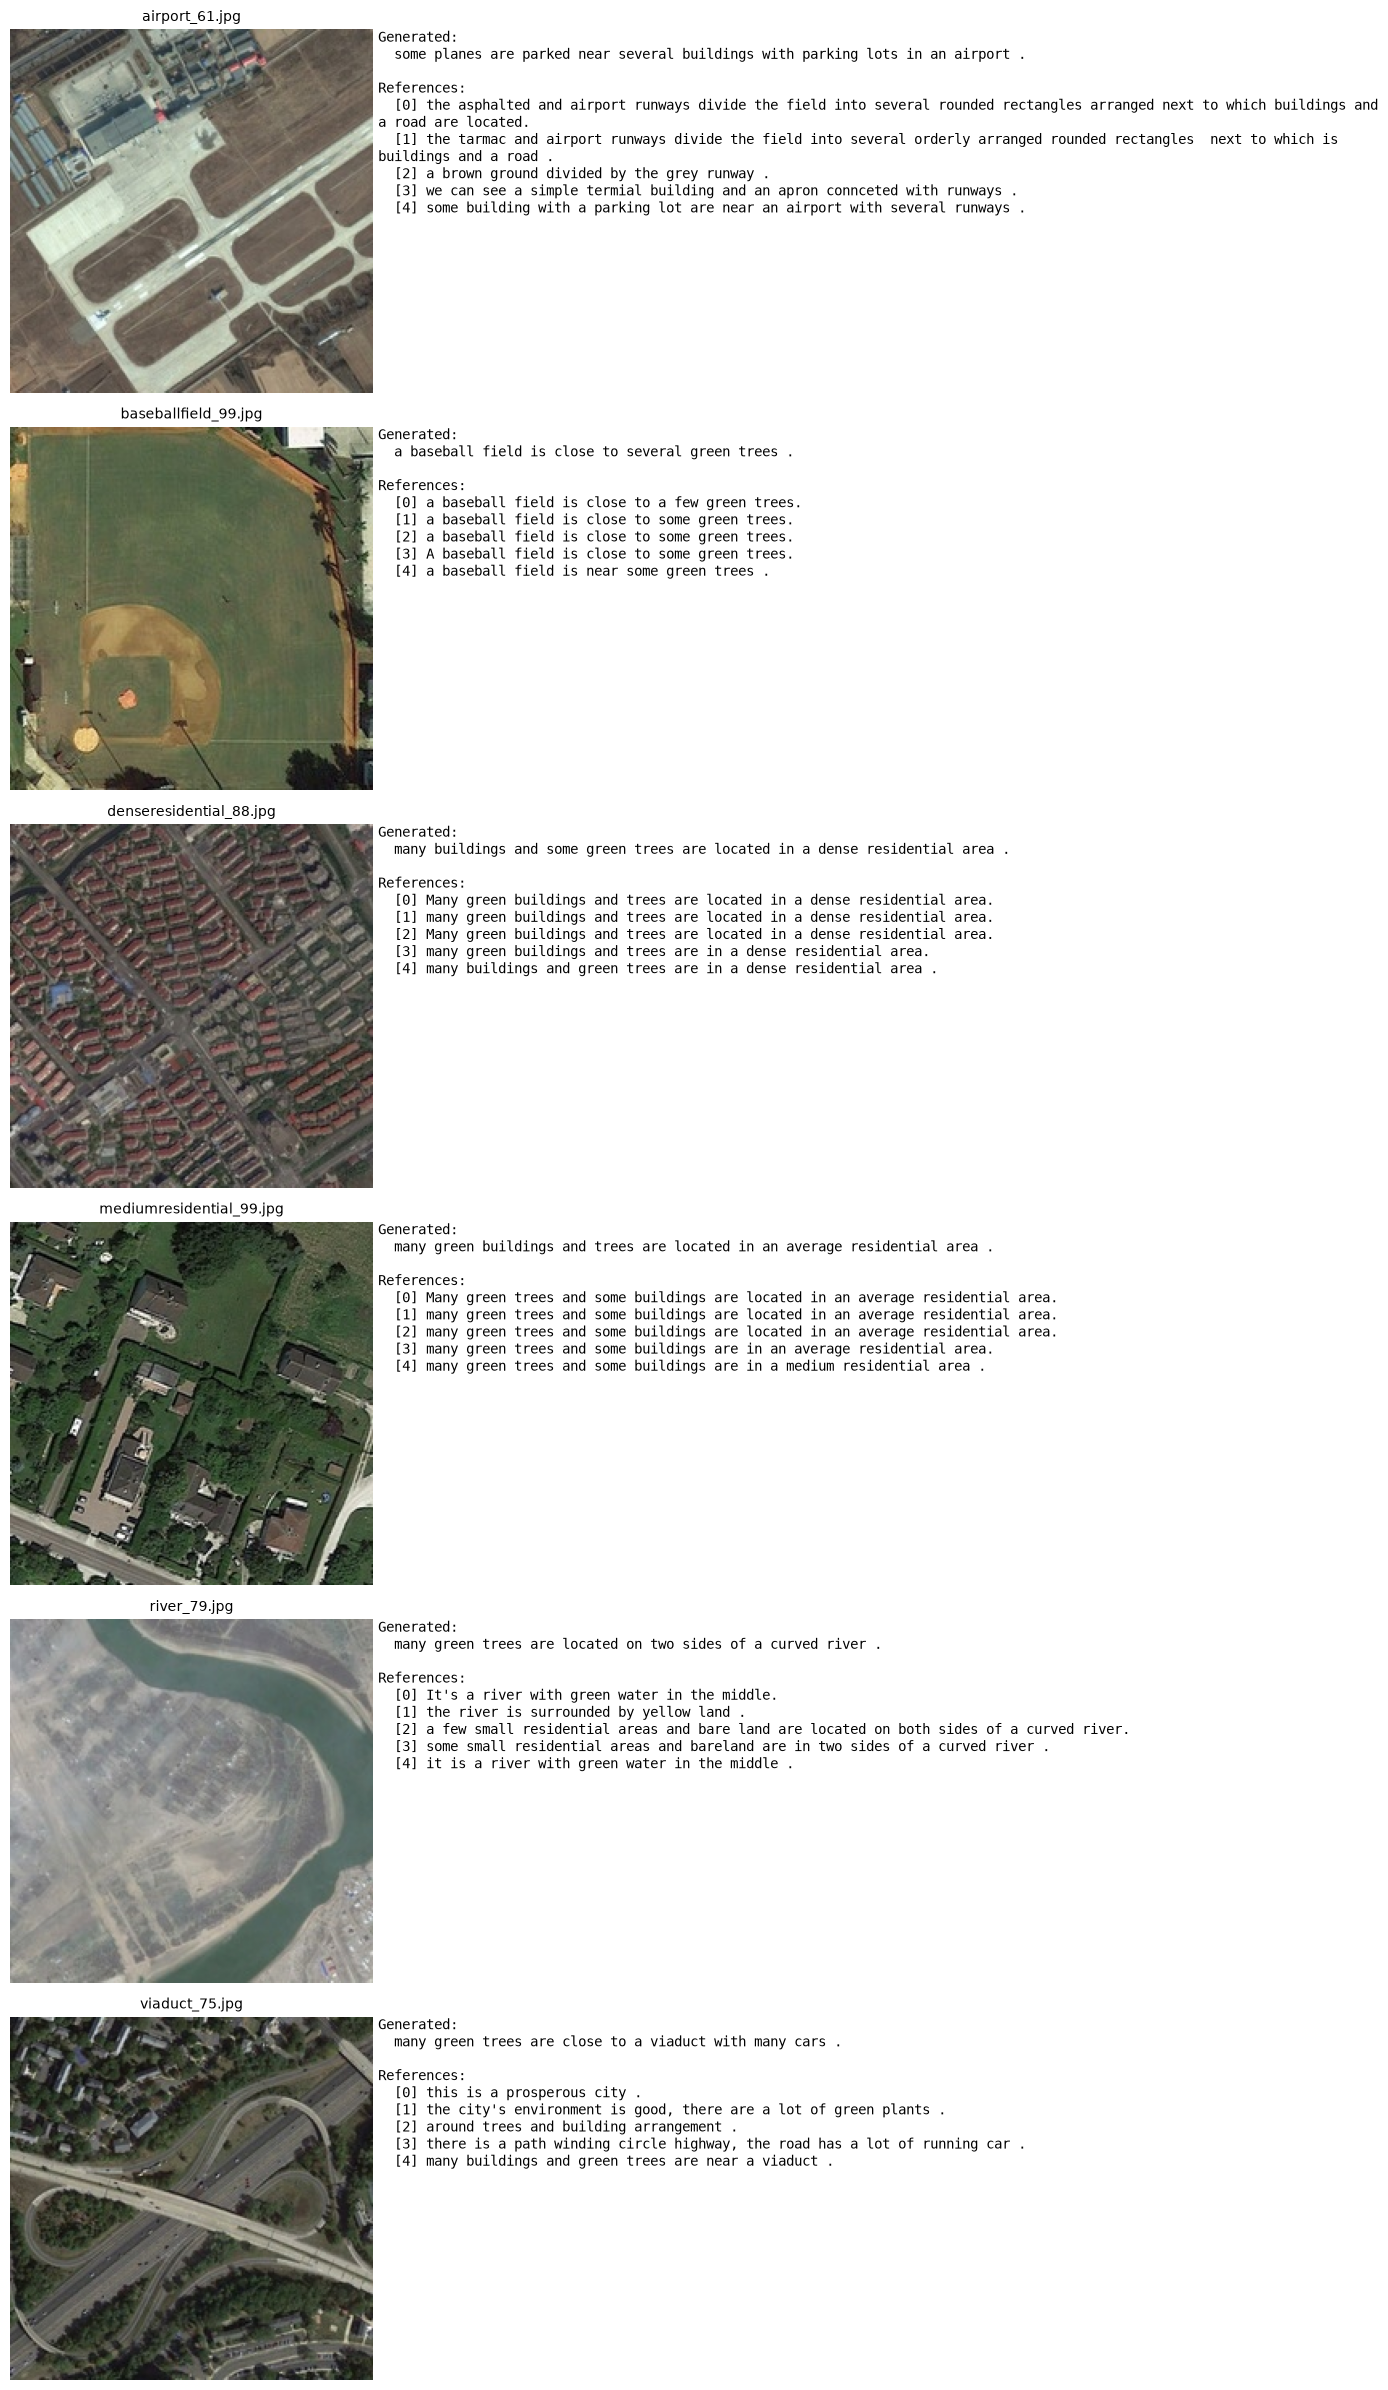

Figure saved to docs/figures/baseline_generation_examples.png


In [26]:
NUM_EXAMPLES = 6
INDICES = [0, 100, 300, 500, 800, 1000]

fig, axes = plt.subplots(NUM_EXAMPLES, 2, figsize=(14, 4 * NUM_EXAMPLES),
                         gridspec_kw={"width_ratios": [1, 2.2]})

for row, idx in enumerate(INDICES):
    entry = valid_data[idx]
    img_path = IMAGES_ROOT / "valid" / entry["filename"]
    pil_image = Image.open(img_path).convert("RGB")

    image_tensor = eval_transform(pil_image).unsqueeze(0).to(device)
    generated = model.generate(image_tensor, bos_idx=BOS_IDX, eos_idx=EOS_IDX, max_len=MAX_LEN)
    caption = decode(generated[0].tolist())

    ax_img = axes[row, 0]
    ax_img.imshow(pil_image)
    ax_img.axis("off")
    ax_img.set_title(entry["filename"], fontsize=10)

    ax_text = axes[row, 1]
    ax_text.axis("off")
    text = f"Generated:\n  {caption}\n\nReferences:\n"
    for i, ref in enumerate(entry["captions"]):
        text += f"  [{i}] {ref}\n"
    ax_text.text(0, 1, text, va="top", ha="left", fontsize=10, family="monospace",
                 wrap=True, transform=ax_text.transAxes)

plt.tight_layout()
plt.savefig("docs/figures/baseline_generation_examples.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Figure saved to docs/figures/baseline_generation_examples.png")

In [27]:
from tqdm import tqdm

GEN_BATCH_SIZE = 32

def tokenize_reference(caption):
    caption = caption.lower()
    caption = re.sub(r"([.,!?;:\"'()])", r" \1 ", caption)
    return caption.split()

def generate_for_split(split_data, split_name):
    all_generated = []
    all_references = []

    for start in tqdm(range(0, len(split_data), GEN_BATCH_SIZE), desc=f"Generating ({split_name})"):
        batch_entries = split_data[start:start + GEN_BATCH_SIZE]

        images = []
        for entry in batch_entries:
            img_path = IMAGES_ROOT / split_name / entry["filename"]
            pil_image = Image.open(img_path).convert("RGB")
            images.append(eval_transform(pil_image))
        images = torch.stack(images).to(device)

        generated = model.generate(images, bos_idx=BOS_IDX, eos_idx=EOS_IDX, max_len=MAX_LEN)

        for i, entry in enumerate(batch_entries):
            caption = decode(generated[i].tolist())
            hypothesis = caption.split()
            references = [tokenize_reference(ref) for ref in entry["captions"]]
            all_generated.append(hypothesis)
            all_references.append(references)

    return all_generated, all_references

valid_generated, valid_references = generate_for_split(valid_data, "valid")

print(f"\nGenerated captions: {len(valid_generated)}")
print(f"References sets:    {len(valid_references)}")
print(f"\nSample #0:")
print(f"  Generated: {' '.join(valid_generated[0])}")
print(f"  Reference [0]: {' '.join(valid_references[0][0])}")

Generating (valid): 100%|██████████| 35/35 [00:04<00:00,  8.51it/s]


Generated captions: 1094
References sets:    1094

Sample #0:
  Generated: some planes are parked near several buildings with parking lots in an airport .
  Reference [0]: the asphalted and airport runways divide the field into several rounded rectangles arranged next to which buildings and a road are located .


In [28]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

smoothing = SmoothingFunction().method1

bleu_1 = corpus_bleu(valid_references, valid_generated, weights=(1.0, 0, 0, 0), smoothing_function=smoothing)
bleu_2 = corpus_bleu(valid_references, valid_generated, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothing)
bleu_3 = corpus_bleu(valid_references, valid_generated, weights=(1/3, 1/3, 1/3, 0), smoothing_function=smoothing)
bleu_4 = corpus_bleu(valid_references, valid_generated, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)

print("BLEU scores (validation set, greedy decoding):")
print(f"  BLEU-1: {bleu_1:.4f}")
print(f"  BLEU-2: {bleu_2:.4f}")
print(f"  BLEU-3: {bleu_3:.4f}")
print(f"  BLEU-4: {bleu_4:.4f}")

BLEU scores (validation set, greedy decoding):
  BLEU-1: 0.7263
  BLEU-2: 0.5879
  BLEU-3: 0.4909
  BLEU-4: 0.4186


In [29]:
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.rouge.rouge import Rouge

gts = {i: [" ".join(refs) for refs in valid_references[i]] for i in range(len(valid_references))}
res = {i: [" ".join(valid_generated[i])] for i in range(len(valid_generated))}

cider_scorer = Cider()
cider_score, _ = cider_scorer.compute_score(gts, res)

rouge_scorer = Rouge()
rouge_score, _ = rouge_scorer.compute_score(gts, res)

print("Advanced metrics (validation set, greedy decoding):")
print(f"  CIDEr:   {cider_score:.4f}")
print(f"  ROUGE-L: {rouge_score:.4f}")

Advanced metrics (validation set, greedy decoding):
  CIDEr:   2.0663
  ROUGE-L: 0.6545


In [30]:
baseline_metrics = {
    "BLEU-1":  bleu_1,
    "BLEU-2":  bleu_2,
    "BLEU-3":  bleu_3,
    "BLEU-4":  bleu_4,
    "ROUGE-L": rouge_score,
    "CIDEr":   cider_score,
}

print("=" * 50)
print("Baseline Show and Tell — Validation metrics")
print("=" * 50)
for name, value in baseline_metrics.items():
    print(f"  {name:<10} {value:.4f}")
print("=" * 50)

Baseline Show and Tell — Validation metrics
  BLEU-1     0.7263
  BLEU-2     0.5879
  BLEU-3     0.4909
  BLEU-4     0.4186
  ROUGE-L    0.6545
  CIDEr      2.0663


## 8. Full model

Starting from the baseline, we train a single full model that integrates all our proposed enhancements:

1. **Dropout** (p=0.3) in the decoder — architectural regularization.
2. **Data augmentation** on training images (horizontal/vertical flips, 90°/180°/270° rotations) — input-side regularization.
3. **Label smoothing** (ε=0.1) in the cross-entropy loss — target-side regularization.
4. **Weight decay** (1e-5) in the Adam optimizer — classical L2 regularization on parameters.
5. **Encoder fine-tuning** of the last residual block (`layer4`), with two parameter groups: decoder at `lr=1e-4`, encoder at `lr=1e-5` (10× smaller to preserve the ImageNet pre-training).
6. **Beam search decoding** (K=5, length penalty α=0.7) at inference time, replacing greedy decoding.

The model is not initialized from the baseline weights, but trained independently from random decoder weights and an ImageNet-pretrained encoder, with early stopping (patience 4) and a cap of 25 epochs. At the end it is evaluated on the validation set with beam search and compared against the baseline.

In [31]:
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)


def generate_for_split_beam(split_data, split_name, beam_width=5, length_alpha=0.7):
    all_generated = []
    all_references = []

    for entry in tqdm(split_data, desc=f"Generating beam-{beam_width} ({split_name})"):
        img_path = IMAGES_ROOT / split_name / entry["filename"]
        pil_image = Image.open(img_path).convert("RGB")
        image_tensor = eval_transform(pil_image).unsqueeze(0).to(device)

        generated = model.generate_beam(image_tensor, bos_idx=BOS_IDX, eos_idx=EOS_IDX, max_len=MAX_LEN,
                                        beam_width=beam_width, length_alpha=length_alpha)
        caption = decode(generated)
        hypothesis = caption.split()
        references = [tokenize_reference(ref) for ref in entry["captions"]]

        all_generated.append(hypothesis)
        all_references.append(references)

    return all_generated, all_references

In [32]:
augment_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomChoice([
        transforms.RandomRotation((0, 0)),
        transforms.RandomRotation((90, 90)),
        transforms.RandomRotation((180, 180)),
        transforms.RandomRotation((270, 270)),
    ]),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_set_aug = RSICDDataset(train_data, IMAGES_ROOT / "train", augment_transform)
train_loader_aug = DataLoader(train_set_aug, batch_size=BATCH_SIZE, shuffle=True,
                               num_workers=NUM_WORKERS, collate_fn=collate_fn)

print(f"Augmented train set: {len(train_set_aug)} samples, {len(train_loader_aug)} batches")

Augmented train set: 43670 samples, 1365 batches


In [33]:
model_full = ShowAndTell(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_layers=NUM_LAYERS,
    pad_idx=PAD_IDX,
    dropout=0.3,
).to(device)

model_full.encoder.unfreeze_last_block()

total_params = sum(p.numel() for p in model_full.parameters())
trainable_params = sum(p.numel() for p in model_full.parameters() if p.requires_grad)
frozen_params = total_params - trainable_params

print(f"Total parameters:        {total_params:>12,}")
print(f"Trainable parameters:    {trainable_params:>12,}")
print(f"Frozen parameters:       {frozen_params:>12,}")
print(f"Trainable / Total:       {trainable_params/total_params*100:>11.2f}%")

Total parameters:          26,985,363
Trainable parameters:      18,442,067
Frozen parameters:          8,543,296
Trainable / Total:             68.34%


In [34]:
RUN_NAME_FULL = "full"
CHECKPOINT_PATH_FULL = CHECKPOINT_DIR / f"{RUN_NAME_FULL}_best.pt"

DECODER_LR = 1e-4
ENCODER_LR = 1e-5
WEIGHT_DECAY = 1e-5

criterion_full = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.1)

encoder_trainable_params = [p for p in model_full.encoder.parameters() if p.requires_grad]
decoder_trainable_params = [p for p in model_full.decoder.parameters() if p.requires_grad]

optimizer_full = torch.optim.Adam([
    {"params": decoder_trainable_params, "lr": DECODER_LR, "weight_decay": WEIGHT_DECAY},
    {"params": encoder_trainable_params, "lr": ENCODER_LR, "weight_decay": WEIGHT_DECAY},
])

writer_full = SummaryWriter(log_dir=f"runs/{RUN_NAME_FULL}")

print(f"Run name:        {RUN_NAME_FULL}")
print(f"Checkpoint path: {CHECKPOINT_PATH_FULL}")
print(f"TensorBoard log: runs/{RUN_NAME_FULL}")
print(f"Loss:            CrossEntropyLoss(ignore_index={PAD_IDX}, label_smoothing=0.1)")
print(f"Optimizer:       Adam with two parameter groups")
print(f"  decoder lr:    {DECODER_LR}")
print(f"  encoder lr:    {ENCODER_LR}  ({DECODER_LR/ENCODER_LR:.0f}x smaller)")
print(f"  weight decay:  {WEIGHT_DECAY}")

Run name:        full
Checkpoint path: checkpoints\full_best.pt
TensorBoard log: runs/full
Loss:            CrossEntropyLoss(ignore_index=0, label_smoothing=0.1)
Optimizer:       Adam with two parameter groups
  decoder lr:    0.0001
  encoder lr:    1e-05  (10x smaller)
  weight decay:  1e-05


In [76]:
NUM_EPOCHS_FULL = 25
PATIENCE_FULL = 4

best_val_loss_full = float("inf")
epochs_without_improvement_full = 0
history_full = {"train_loss": [], "val_loss": []}

for epoch in range(1, NUM_EPOCHS_FULL + 1):
    train_loss = train_one_epoch(model_full, train_loader_aug, criterion_full, optimizer_full, device)
    val_loss = evaluate(model_full, valid_loader, criterion_full, device)

    history_full["train_loss"].append(train_loss)
    history_full["val_loss"].append(val_loss)
    writer_full.add_scalar("loss/train", train_loss, epoch)
    writer_full.add_scalar("loss/val", val_loss, epoch)

    improved = val_loss < best_val_loss_full
    marker = " <- new best" if improved else ""
    print(f"Epoch {epoch:2d}/{NUM_EPOCHS_FULL} | train loss: {train_loss:.4f} | val loss: {val_loss:.4f}{marker}")

    if improved:
        best_val_loss_full = val_loss
        epochs_without_improvement_full = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model_full.state_dict(),
            "val_loss": val_loss,
        }, CHECKPOINT_PATH_FULL)
    else:
        epochs_without_improvement_full += 1
        if epochs_without_improvement_full >= PATIENCE_FULL:
            print(f"Early stopping triggered after {epoch} epochs")
            break

writer_full.close()
print(f"\nBest validation loss: {best_val_loss_full:.4f}")

Epoch  1/25 | train loss: 3.4239 | val loss: 2.8852 <- new best


Epoch  2/25 | train loss: 2.7004 | val loss: 2.7091 <- new best


Epoch  3/25 | train loss: 2.5168 | val loss: 2.6180 <- new best


Epoch  4/25 | train loss: 2.4082 | val loss: 2.5797 <- new best


Epoch  5/25 | train loss: 2.3334 | val loss: 2.5419 <- new best


...

Epoch 11/25 | train loss: 2.1135 | val loss: 2.5026 <- new best


Epoch 12/25 | train loss: 2.0917 | val loss: 2.5097


Epoch 13/25 | train loss: 2.0691 | val loss: 2.5082


Epoch 14/25 | train loss: 2.0499 | val loss: 2.5094


Epoch 15/25 | train loss: 2.0308 | val loss: 2.5157
Early stopping triggered after 15 epochs

Best validation loss: 2.5026


In [35]:
checkpoint_full = torch.load(CHECKPOINT_PATH_FULL, map_location=device, weights_only=True)
model_full.load_state_dict(checkpoint_full["model_state_dict"])
model_full.to(device)
model_full.eval()

print(f"Loaded full checkpoint:")
print(f"  file:      {CHECKPOINT_PATH_FULL}")
print(f"  epoch:     {checkpoint_full['epoch']}")
print(f"  val loss:  {checkpoint_full['val_loss']:.4f}")

Loaded full checkpoint:
  file:      checkpoints\full_best.pt
  epoch:     11
  val loss:  2.5026


In [36]:
model_to_eval = model
model = model_full

valid_generated_full, valid_references_full = generate_for_split_beam(valid_data, "valid", beam_width=5, length_alpha=0.7)

model = model_to_eval
del model_to_eval

print(f"\nGenerated beam captions: {len(valid_generated_full)}")
print(f"\nSample #0: {' '.join(valid_generated_full[0])}")

Generating beam-5 (valid): 100%|██████████| 1094/1094 [00:35<00:00, 30.43it/s]


Generated beam captions: 1094

Sample #0: many planes are parked near a terminal in an airport .


In [37]:
bleu_1_full = corpus_bleu(valid_references_full, valid_generated_full, weights=(1.0, 0, 0, 0), smoothing_function=smoothing)
bleu_2_full = corpus_bleu(valid_references_full, valid_generated_full, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothing)
bleu_3_full = corpus_bleu(valid_references_full, valid_generated_full, weights=(1/3, 1/3, 1/3, 0), smoothing_function=smoothing)
bleu_4_full = corpus_bleu(valid_references_full, valid_generated_full, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)

gts_full = {i: [" ".join(refs) for refs in valid_references_full[i]] for i in range(len(valid_references_full))}
res_full = {i: [" ".join(valid_generated_full[i])] for i in range(len(valid_generated_full))}
cider_full, _ = Cider().compute_score(gts_full, res_full)
rouge_full, _ = Rouge().compute_score(gts_full, res_full)

full_metrics = {
    "BLEU-1":  bleu_1_full,
    "BLEU-2":  bleu_2_full,
    "BLEU-3":  bleu_3_full,
    "BLEU-4":  bleu_4_full,
    "ROUGE-L": rouge_full,
    "CIDEr":   cider_full,
}

print("=" * 70)
print(f"{'Metric':<10} {'Baseline (greedy)':<22} {'Full (beam-5)':<18} {'Delta':<10}")
print("=" * 70)
for name in baseline_metrics:
    base = baseline_metrics[name]
    full = full_metrics[name]
    delta = full - base
    rel = (delta / base) * 100
    print(f"  {name:<8} {base:>8.4f}             {full:>8.4f}        {delta:>+.4f} ({rel:>+.1f}%)")
print("=" * 70)

Metric     Baseline (greedy)      Full (beam-5)      Delta     
  BLEU-1     0.7263               0.7695        +0.0431 (+5.9%)
  BLEU-2     0.5879               0.6432        +0.0553 (+9.4%)
  BLEU-3     0.4909               0.5518        +0.0608 (+12.4%)
  BLEU-4     0.4186               0.4824        +0.0638 (+15.2%)
  ROUGE-L    0.6545               0.6962        +0.0416 (+6.4%)
  CIDEr      2.0663               2.4607        +0.3945 (+19.1%)


## 9. Test set evaluation

Final evaluation of the baseline (greedy decoding) and the full model (beam search, K=5) on the test set. The test set has been untouched until this point and is used here only for the final comparison.

In [41]:
model.load_state_dict(torch.load(checkpoint_path, weights_only=True)["model_state_dict"])
model.eval()
model.to(device)

test_generated_baseline, test_references_baseline = generate_for_split(test_data, "test")

print(f"Generated greedy captions on test: {len(test_generated_baseline)}")

Generating (test): 100%|██████████| 35/35 [00:05<00:00,  6.90it/s]

Generated greedy captions on test: 1093


In [42]:
bleu_1_test_base = corpus_bleu(test_references_baseline, test_generated_baseline, weights=(1.0, 0, 0, 0),      smoothing_function=smoothing)
bleu_2_test_base = corpus_bleu(test_references_baseline, test_generated_baseline, weights=(0.5, 0.5, 0, 0),    smoothing_function=smoothing)
bleu_3_test_base = corpus_bleu(test_references_baseline, test_generated_baseline, weights=(1/3, 1/3, 1/3, 0),  smoothing_function=smoothing)
bleu_4_test_base = corpus_bleu(test_references_baseline, test_generated_baseline, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)

gts_test_base = {i: [" ".join(refs) for refs in test_references_baseline[i]] for i in range(len(test_references_baseline))}
res_test_base = {i: [" ".join(test_generated_baseline[i])] for i in range(len(test_generated_baseline))}
cider_test_base, _ = Cider().compute_score(gts_test_base, res_test_base)
rouge_test_base, _ = Rouge().compute_score(gts_test_base, res_test_base)

baseline_test_metrics = {
    "BLEU-1":  bleu_1_test_base,
    "BLEU-2":  bleu_2_test_base,
    "BLEU-3":  bleu_3_test_base,
    "BLEU-4":  bleu_4_test_base,
    "ROUGE-L": rouge_test_base,
    "CIDEr":   cider_test_base,
}

In [43]:
model_full.load_state_dict(torch.load(CHECKPOINT_PATH_FULL, weights_only=True)["model_state_dict"])
model_full.eval()
model_full.to(device)

model_to_eval = model
model = model_full

test_generated_full, test_references_full = generate_for_split_beam(test_data, "test", beam_width=5, length_alpha=0.7)

model = model_to_eval
del model_to_eval

print(f"Generated beam captions on test: {len(test_generated_full)}")

Generating beam-5 (test): 100%|██████████| 1093/1093 [00:39<00:00, 27.45it/s]

Generated beam captions on test: 1093


In [44]:
bleu_1_test_full = corpus_bleu(test_references_full, test_generated_full, weights=(1.0, 0, 0, 0),      smoothing_function=smoothing)
bleu_2_test_full = corpus_bleu(test_references_full, test_generated_full, weights=(0.5, 0.5, 0, 0),    smoothing_function=smoothing)
bleu_3_test_full = corpus_bleu(test_references_full, test_generated_full, weights=(1/3, 1/3, 1/3, 0),  smoothing_function=smoothing)
bleu_4_test_full = corpus_bleu(test_references_full, test_generated_full, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothing)

gts_test_full = {i: [" ".join(refs) for refs in test_references_full[i]] for i in range(len(test_references_full))}
res_test_full = {i: [" ".join(test_generated_full[i])] for i in range(len(test_generated_full))}
cider_test_full, _ = Cider().compute_score(gts_test_full, res_test_full)
rouge_test_full, _ = Rouge().compute_score(gts_test_full, res_test_full)

full_test_metrics = {
    "BLEU-1":  bleu_1_test_full,
    "BLEU-2":  bleu_2_test_full,
    "BLEU-3":  bleu_3_test_full,
    "BLEU-4":  bleu_4_test_full,
    "ROUGE-L": rouge_test_full,
    "CIDEr":   cider_test_full,
}

In [45]:
print("=" * 70)
print(f"{'Metric':<10} {'Baseline (greedy)':<22} {'Full (beam-5)':<18} {'Delta':<10}")
print("=" * 70)
for name in baseline_test_metrics:
    base = baseline_test_metrics[name]
    full = full_test_metrics[name]
    delta = full - base
    rel = (delta / base) * 100
    print(f"  {name:<8} {base:>8.4f}              {full:>8.4f}          {delta:>+.4f} ({rel:>+.1f}%)")
print("=" * 70)

Metric     Baseline (greedy)      Full (beam-5)      Delta     
  BLEU-1     0.6478                0.6696          +0.0218 (+3.4%)
  BLEU-2     0.4365                0.4714          +0.0349 (+8.0%)
  BLEU-3     0.3134                0.3502          +0.0368 (+11.7%)
  BLEU-4     0.2335                0.2696          +0.0361 (+15.5%)
  ROUGE-L    0.4931                0.5147          +0.0216 (+4.4%)
  CIDEr      0.7053                0.7942          +0.0889 (+12.6%)


In [ ]:
# 1. Average reference length in the two splits
val_ref_lengths  = [len(r) for refs in valid_references_full for r in refs]
test_ref_lengths = [len(r) for refs in test_references_full for r in refs]
print(f"Validation references: avg len = {sum(val_ref_lengths)/len(val_ref_lengths):.2f} tokens")
print(f"Test references:       avg len = {sum(test_ref_lengths)/len(test_ref_lengths):.2f} tokens")

# 2. Distinct reference vocabulary
val_vocab  = set(tok for refs in valid_references_full for r in refs for tok in r)
test_vocab = set(tok for refs in test_references_full for r in refs for tok in r)
print(f"Validation references: {len(val_vocab)} distinct tokens")
print(f"Test references:       {len(test_vocab)} distinct tokens")

# 3. Average length of captions generated by the full model
val_gen_lengths  = [len(c) for c in valid_generated_full]
test_gen_lengths = [len(c) for c in test_generated_full]
print(f"Full generated on val:  avg len = {sum(val_gen_lengths)/len(val_gen_lengths):.2f}")
print(f"Full generated on test: avg len = {sum(test_gen_lengths)/len(test_gen_lengths):.2f}")

Validation references: avg len = 10.22 tokens
Test references:       avg len = 12.43 tokens
Validation references: 1213 distinct tokens
Test references:       1778 distinct tokens
Full generated on val:  avg len = 11.14
Full generated on test: avg len = 11.03


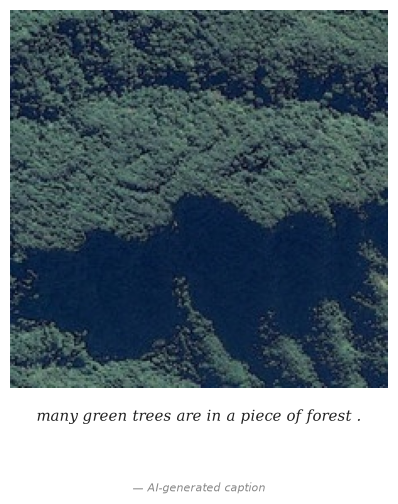

In [90]:
#Final demo: given a random image from the test set, display the caption generated by the final model using beam search

import random

random_entry = random.choice(test_data)
img_path = IMAGES_ROOT / "test" / random_entry["filename"]
pil_image = Image.open(img_path).convert("RGB")

image_tensor = eval_transform(pil_image).unsqueeze(0).to(device)
generated_tokens = model_full.generate_beam(
    image_tensor, bos_idx=BOS_IDX, eos_idx=EOS_IDX,
    max_len=MAX_LEN, beam_width=5, length_alpha=0.7,
)
caption = decode(generated_tokens)

fig, ax = plt.subplots(figsize=(5, 6))
ax.imshow(pil_image)
ax.axis("off")

ax.text(
    0.5, -0.05, caption,
    transform=ax.transAxes,
    ha="center", va="top",
    fontsize=11, fontstyle="italic", color="#222222",
    family="serif",
    linespacing=1.3,
)

ax.text(
    0.5, -0.25, "— AI-generated caption",
    transform=ax.transAxes,
    ha="center", va="top",
    fontsize=8, color="#888888",
    family="sans-serif",
    style="italic",
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)
    spine.set_edgecolor("#dddddd")

plt.subplots_adjust(bottom=0.25)
plt.show()